In [ ]:
#%pip install neo4j pandas tqdm numpy scipy scikit-learn networkx matplotlib

# Bagian 1.1 - 1.2

In [ ]:
import pandas as pd
from neo4j import GraphDatabase, RoutingControl
from tqdm import tqdm
import numpy as np
from scipy.sparse import csr_matrix
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Konfigurasi Koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "-pasword-")

In [4]:
# 2. Fungsi Membuat Node & Relasi (Bagian 1.2 No. 3)
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j"
    )

# 3. Fungsi Menampilkan Relasi (Bagian 1.2 No. 4)
def print_friends(driver, name):
    records, summary, keys = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ
    )
    for record in records:
        print(record["friend.name"])

# 4. Menjalankan Kode (Testing Connection)
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


Checkpint 1.2
1. Nama database: neo4j.  
2. Akses DDL/DML CYPHER lain untuk berpindah/mengakses database dalam 1 instance: Menggunakan sintaks USE <database_name> sebelum klausa query CYPHER (misal: USE system atau USE myotherdb).   
3. Jenis graf pertemanan: Directed Graph (Graf Berarah), karena relasi [:KNOWS] dibuat dengan tanda panah searah dari (a) menuju (friend) ((a)-[:KNOWS]->(friend)).   

In [5]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
print("Database Neo4j telah dibersihkan!")

Database Neo4j telah dibersihkan!


# Soal 2.1 No. 1 dan 2 Filter Periode Waktu

In [ ]:
df = pd.read_csv("data/events.csv")
df.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [ ]:
# Konversi timestamp (Unix epoch ms) ke datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

p1_start, p1_end = "2015-06-15", "2015-06-25"
p2_start, p2_end = "2015-07-15", "2015-07-20"

df_p1 = df[(df['datetime'] >= p1_start) & (df['datetime'] <= p1_end)]
df_p2 = df[(df['datetime'] >= p2_start) & (df['datetime'] <= p2_end)]


print(f"Data P1: {len(df_p1)} baris, Data P2: {len(df_p2)} baris.")

Data P1: 214846 baris, Data P2: 99252 baris.


In [ ]:
# Menyimpan P1 dan P2 ke file terpisah
df_p1.to_csv("p1_train.csv", index=False)
df_p2.to_csv("p2_test.csv", index=False)

print("Data P1 dan P2 berhasil dipisah dan disimpan!")

Data P1 dan P2 berhasil dipisah dan disimpan!


# import batch (Bagian 1.3)

In [ ]:
# Fungsi Cypher untuk Impor Batch
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# Proses Batching
batch_size = 5000
csv_file_path = "data/p1_train.csv"

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        # Opsional: Buat Constraint Index agar impor cepat
        session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
        session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
        
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
        
        for chunk in tqdm(chunks, desc="Mengimpor Batch Data ke Neo4j"):
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)

print("Impor data ke Neo4j selesai!")

Mengimpor Batch Data ke Neo4j: 0it [00:00, ?it/s]Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=6, column=5, offset=138>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 138, 'line': 6, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\

Impor data ke Neo4j selesai!


Untuk menjaga efisiensi memori dan mempercepat waktu eksekusi, seluruh data interaksi pada periode P1 diimpor ke dalam *database* Neo4j menggunakan teknik *batching* sebesar 5.000 baris per iterasi. 

Setiap *batch* diproses menggunakan perintah `UNWIND` pada Cypher SQL untuk membangun struktur graf secara otomatis. Melalui skrip ini, sistem mengekstrak setiap baris data menjadi simpul (*node*) untuk entitas `Visitor` dan `Item`, lalu merelasikan keduanya menggunakan garis penghubung (*relationship*) spesifik seperti `[:VIEWED]`, `[:ADDED_TO_CART]`, atau `[:BOUGHT]`, yang disesuaikan dengan rekaman *event* aktivitas pengguna.

# Soal 2.1 No. 3 Cek Komposisi Subgraf 

In [6]:
def get_graph_composition(driver):
    with driver.session(database="neo4j") as session:
        # 1. Query menghitung jenis dan jumlah Simpul (Node)
        print("KOMPOSISI SIMPUL (NODE)")
        node_query = """
        MATCH (n)
        RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
        """
        node_results = session.run(node_query)
        for record in node_results:
            print(f"Simpul {record['jenis_simpul']}: {record['jumlah']}")

        # 2. Query menghitung jenis dan jumlah Relasi (Relationship)
        print("\nKOMPOSISI RELASI (RELATIONSHIP)")
        rel_query = """
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        """
        rel_results = session.run(rel_query)
        for record in rel_results:
            print(f"Relasi {record['jenis_relasi']}: {record['jumlah']}")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    get_graph_composition(driver)

KOMPOSISI SIMPUL (NODE)
Simpul Visitor: 111410
Simpul Item: 64554

KOMPOSISI RELASI (RELATIONSHIP)
Relasi VIEWED: 207018
Relasi BOUGHT: 1977
Relasi ADDED_TO_CART: 5851
Relasi SIMILAR: 5
Relasi SIMILAR_TO: 5


**1. Logika Kueri Simpul (Node)**
* `MATCH (n)`: Memindai dan memetakan seluruh simpul (*node*) yang ada di dalam *database* graf.
* `RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah`: Mengekstrak label utama dari setiap simpul, kemudian mengelompokkan dan menghitung total kuantitas dari masing-masing entitas tersebut.

**2. Logika Kueri Relasi (Relationship)**
* `MATCH ()-[r]->()`: Memindai seluruh garis interaksi berarah yang menghubungkan antar simpul di dalam graf, lalu mendefinisikannya ke dalam variabel `r`.
* `RETURN type(r) AS jenis_relasi, count(r) AS jumlah`: Mengekstrak tipe interaksi, kemudian mengelompokkan dan menghitung total frekuensi untuk setiap jenis relasi tersebut.

Berdasarkan *output* eksekusi kueri di atas, *database* graf saat ini terbentuk dari dua jenis entitas utama, yaitu **111.410** simpul `Visitor` (pengguna) dan **64.554** simpul `Item` (produk). 

Kedua entitas ini saling terhubung membentuk jaringan interaksi historis (*e-commerce event*) dengan rincian:
* **207.018** relasi `VIEWED` (menandakan aktivitas pengguna melihat produk).
* **5.851** relasi `ADDED_TO_CART` (menandakan pengguna memasukkan produk ke keranjang).
* **1.977** relasi `BOUGHT` (menandakan transaksi pembelian yang berhasil diselesaikan).

Selain interaksi historis tersebut, sistem juga mendeteksi keberadaan **5 relasi `SIMILAR`** dan **5 relasi `SIMILAR_TO`**. Munculnya relasi ini mengonfirmasi bahwa proses penulisan kembali (*write-back*) dari hasil perhitungan algoritma KNN (*Cosine Similarity*) antar-Visitor yang dilakukan pada tahap analisis sebelumnya telah sukses tersimpan secara permanen ke dalam graf Neo4j.

# (2.1 No. 4 dan 5) Membuat Vector Space Model (VSM)

In [7]:
print("Mengekstrak data dari Neo4j...")
query = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS user, i.itemId AS item, type(r) AS interaction
"""
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query)
        data = [record.data() for record in result]

df_interactions = pd.DataFrame(data)

# Memberikan bobot pada interaksi
bobot = {'VIEWED': 1, 'ADDED_TO_CART': 2, 'BOUGHT': 3}
df_interactions['weight'] = df_interactions['interaction'].map(bobot)

print("Selesai mengekstrak data. Ukuran Data Interaksi:", df_interactions.shape)

Mengekstrak data dari Neo4j...
Selesai mengekstrak data. Ukuran Data Interaksi: (214846, 4)


In [ ]:
print("SOAL 2.1 NO. 4: VSM USER (Sparse Matrix)")

user_cat = df_interactions['user'].astype('category')
item_cat = df_interactions['item'].astype('category')

user_ids = user_cat.cat.categories
item_ids = item_cat.cat.categories

user_item_matrix = csr_matrix(
    (df_interactions['weight'], (user_cat.cat.codes, item_cat.cat.codes)),
    shape=(user_ids.size, item_ids.size)
)

print("Karakteristik VSM User:")
print(f"- Tipe Matriks: {type(user_item_matrix)}")
print(f"- Dimensi / Shape: {user_item_matrix.shape}")
print(f"- Total Vector (User): {user_item_matrix.shape[0]}")
print(f"- Dimensi Fitur (Item): {user_item_matrix.shape[1]}")
print(f"- Jumlah elemen terisi (Non-Zero): {user_item_matrix.nnz}")

SOAL 2.1 NO. 4: VSM USER (Sparse Matrix)
Karakteristik VSM User:
- Tipe Matriks: <class 'scipy.sparse._csr.csr_matrix'>
- Dimensi / Shape: (111410, 64554)
- Total Vector (User): 111410
- Dimensi Fitur (Item): 64554
- Jumlah elemen terisi (Non-Zero): 166055


Membuat Visualisasi VSM User (Sampel 15 User Aktif)...


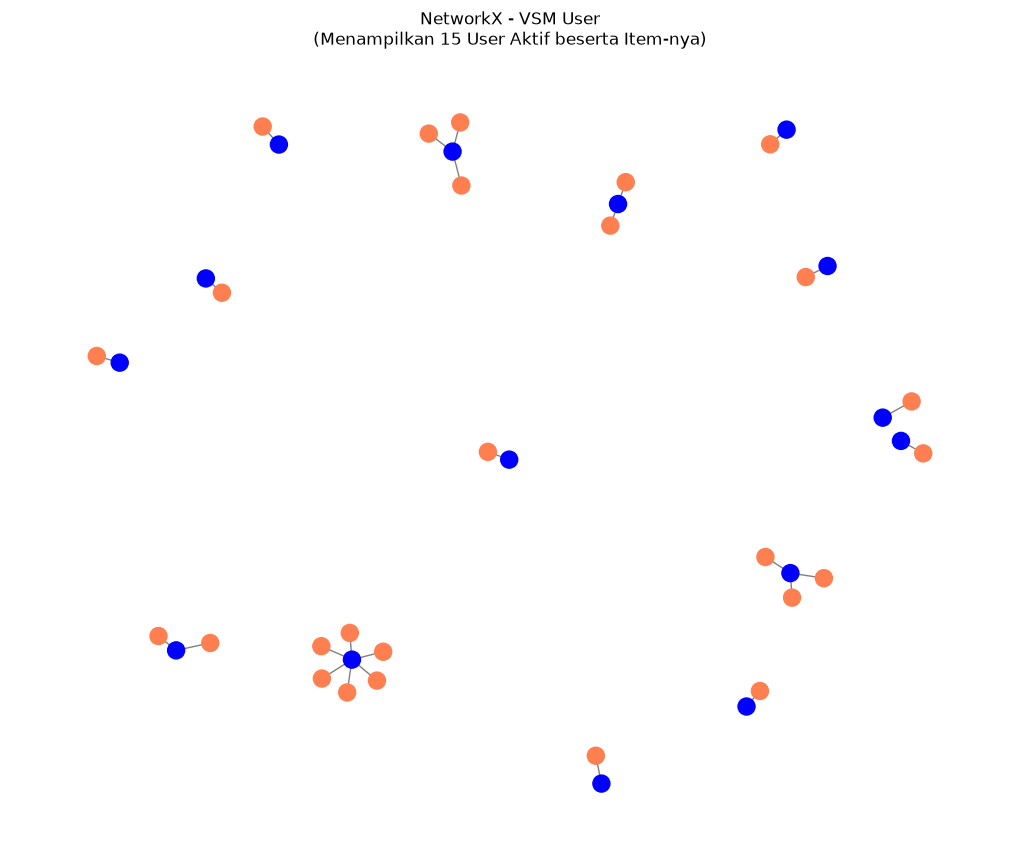

In [9]:
print("Membuat Visualisasi VSM User (Sampel 15 User Aktif)...")

# Mengambil index user yang memiliki minimal 1 interaksi
user_berinteraksi_idx = np.flatnonzero(np.diff(user_item_matrix.indptr) > 0)
sample_user_idx = user_berinteraksi_idx[:15]

G_user = nx.Graph()

for u_idx in sample_user_idx:
    user_node = f"User_{user_ids[u_idx]}"
    G_user.add_node(user_node, tipe="User")

    # Mengambil Item yang pernah diakses oleh User
    item_indices = user_item_matrix[u_idx].indices
    for i_idx in item_indices:
        item_node = f"Item_{item_ids[i_idx]}"
        G_user.add_node(item_node, tipe="Item")
        G_user.add_edge(user_node, item_node)

colors_user = ["blue" if G_user.nodes[n]["tipe"] == "User" else "coral" for n in G_user.nodes()]

plt.figure(figsize=(10, 8))
nx.draw(
    G_user,
    pos=nx.spring_layout(G_user, seed=42),
    node_color=colors_user,
    node_size=150,
    with_labels=False,
    edge_color="gray"
)
plt.title("NetworkX - VSM User\n(Menampilkan 15 User Aktif beserta Item-nya)")
plt.show()

- Dimensi Matriks: 111.410 baris (User) × 64.554 kolom (Item).  
- Kepadatan Data (Sparsity): Matriks berbentuk Sparse Matrix (CSR) yang sangat renggang. Dari miliaran kemungkinan sel, hanya terdapat 166.055 elemen non-zero (interaksi aktual).  
- Karakteristik Visual: Graf NetworkX menampilkan jaringan yang terdistribusi dan renggang. Mayoritas User hanya memiliki sedikit interaksi terhadap Item secara spesifik.  

In [ ]:
print("SOAL 2.1 NO. 5: VSM ITEM (Sparse Matrix)")

item_user_matrix = user_item_matrix.T

print("Karakteristik VSM Item:")
print(f"- Tipe Matriks: {type(item_user_matrix)}")
print(f"- Dimensi / Shape: {item_user_matrix.shape}")
print(f"- Total Vector (Item): {item_user_matrix.shape[0]}")
print(f"- Dimensi Fitur (User): {item_user_matrix.shape[1]}")
print(f"- Jumlah elemen terisi (Non-Zero): {item_user_matrix.nnz}")

SOAL 2.1 NO. 5: VSM ITEM (Sparse Matrix)
Karakteristik VSM Item:
- Tipe Matriks: <class 'scipy.sparse._csc.csc_matrix'>
- Dimensi / Shape: (64554, 111410)
- Total Vector (Item): 64554
- Dimensi Fitur (User): 111410
- Jumlah elemen terisi (Non-Zero): 166055


Membuat Visualisasi VSM Item (Sampel 15 Item Aktif)...


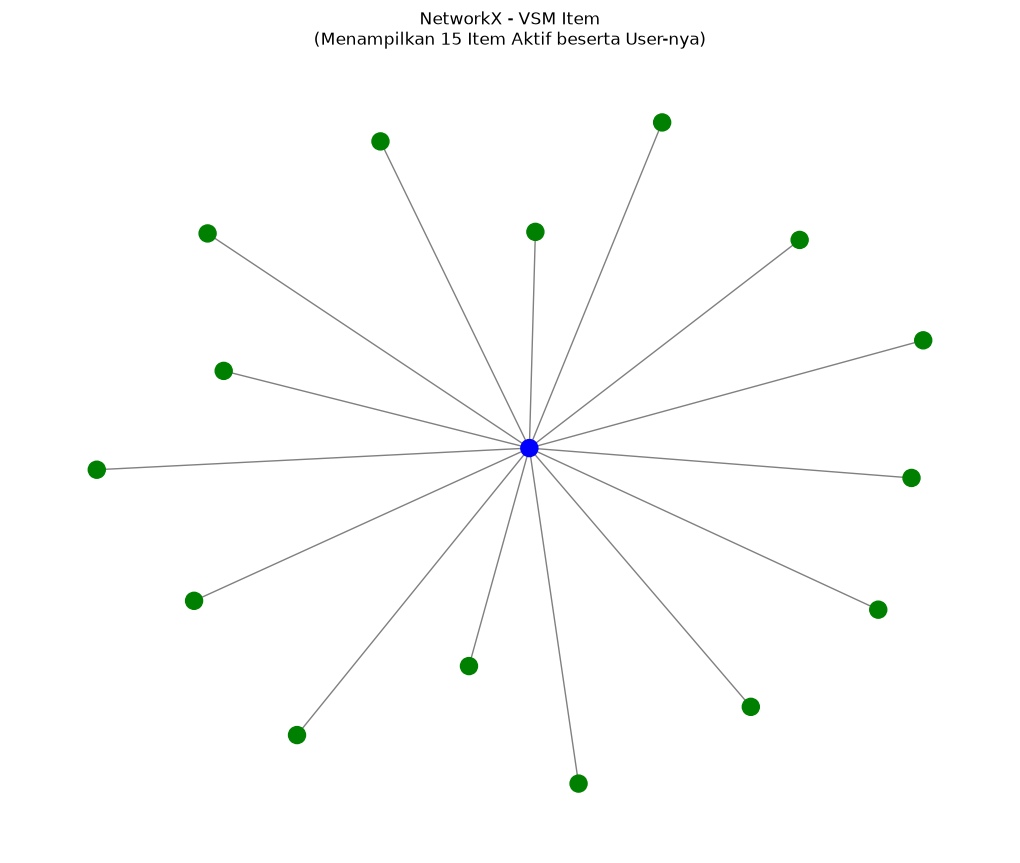

In [11]:
print("Membuat Visualisasi VSM Item (Sampel 15 Item Aktif)...")

# Mengambil index item yang memiliki minimal 1 interaksi
item_berinteraksi_idx = np.flatnonzero(np.diff(item_user_matrix.indptr) > 0)
sample_item_idx = item_berinteraksi_idx[:15]

G_item = nx.Graph()

for i_idx in sample_item_idx:
    item_node = f"Item_{item_ids[i_idx]}"
    G_item.add_node(item_node, tipe="Item")

    # Mengambil Visitor yang pernah berinteraksi dengan Item
    visitor_indices = item_user_matrix[i_idx].indices
    for v_idx in visitor_indices:
        visitor_node = f"User_{user_ids[v_idx]}"
        G_item.add_node(visitor_node, tipe="User")
        G_item.add_edge(item_node, visitor_node)

colors_item = ["green" if G_item.nodes[n]["tipe"] == "Item" else "blue" for n in G_item.nodes()]

plt.figure(figsize=(10, 8))
nx.draw(
    G_item,
    pos=nx.spring_layout(G_item, seed=42),
    node_color=colors_item,
    node_size=150,
    with_labels=False,
    edge_color="gray"
)
plt.title("NetworkX - VSM Item\n(Menampilkan 15 Item Aktif beserta User-nya)")
plt.show()

- Dimensi Matriks: 64.554 baris (Item) × 111.410 kolom (User), yang merupakan bentuk transposisi dari matriks User.   
- Kepadatan Data (Sparsity): Menggunakan representasi Sparse Matrix (CSC) dengan jumlah elemen terisi yang sama, yaitu 166.055 interaksi.  
- Karakteristik Visual: Graf NetworkX memperlihatkan pola star topology sentralistik, di mana sebuah Item yang populer menjadi titik pusat (hub) yang terhubung ke banyak User sekaligus.

# Soal 2.1 No. 6

Proyeksi VSM Item (Item-Based) jauh lebih efektif dan efisien untuk digunakan pada tahap perhitungan similarity selanjutnya.  
- Efisiensi Komputasi: Berdasarkan bentuk matriks, dimensi Item (64.554 vektor) ukurannya hampir setengah dari dimensi User (111.410 vektor). Melakukan proses komputasi perkalian dot/cosine similarity pada 64 ribu baris akan menghemat memori dan waktu eksekusi secara signifikan dibandingkan memproses 111 ribu baris.  
- Kestabilan Pola: Pola interaksi produk e-commerce (seperti terlihat pada sentralitas graf Item) cenderung lebih stabil nilainya dibandingkan pola interaksi user yang sangat acak dan berubah-ubah secara cepat dari waktu ke waktu. 

# Soal 2.1 No. 7 menghitung similarity

In [ ]:
# 1. Menentukan Visitor Target (Mengambil visitor dengan interaksi tertinggi sebagai contoh)
interaction_counts = user_item_matrix.getnnz(axis=1)
target_idx = interaction_counts.argmax()
target_visitor = user_ids[target_idx]

print("Visitor target:", target_visitor)
print("Ada dalam P1 baru:", target_visitor in user_ids)

# 2. Menghitung similarity terhadap seluruh Visitor
similarities = cosine_similarity(
    user_item_matrix[target_idx],
    user_item_matrix
).flatten()

# 3. Mengeluarkan Visitor target dari hasil agar tidak terpilih
similarities[target_idx] = -1

# 4. Mengambil 5 Visitor dengan similarity tertinggi
top5_idx = np.argsort(similarities)[-5:][::-1]


top5_similarity = pd.DataFrame({
    "visitorid": user_ids[top5_idx],
    "similarity": similarities[top5_idx]
})

display(top5_similarity)

Visitor target: 765630
Ada dalam P1 baru: True


,visitorid,similarity
0,1353326,0.290102
1,700658,0.188845
2,1335819,0.186908
3,1316406,0.186908
4,1227637,0.186908


In [13]:
query_save_similarity = """
UNWIND $data AS row
MATCH (v1:Visitor {visitorId: $target})
MATCH (v2:Visitor {visitorId: row.visitorid})
MERGE (v1)-[r:SIMILAR_TO]->(v2)
SET r.score = row.similarity
RETURN count(r) AS jumlah
"""

data_similarity = [
    {
        "visitorid": int(row.visitorid),
        "similarity": float(row.similarity)
    }
    for row in top5_similarity.itertuples(index=False)
]

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(
            query_save_similarity,
            target=int(target_visitor),
            data=data_similarity
        ).single()

        print("Jumlah relationship yang diproses:", result["jumlah"])

Jumlah relationship yang diproses: 5


In [14]:
query_check_similarity = """
MATCH (v1:Visitor {visitorId: $target})-[r:SIMILAR_TO]->(v2:Visitor)
RETURN v1.visitorId AS visitor_target,       
       v2.visitorId AS visitor_mirip,       
       r.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(
            query_check_similarity,
            target=int(target_visitor)
        )

        df_similarity_neo4j = pd.DataFrame(
            [dict(record) for record in result]
        )

print("Hasil pengecekan relasi dari database Neo4j:")
display(df_similarity_neo4j)

Hasil pengecekan relasi dari database Neo4j:


,visitor_target,visitor_mirip,similarity
0,765630,1353326,0.290102
1,765630,700658,0.188845
2,765630,1316406,0.186908
3,765630,1335819,0.186908
4,765630,1227637,0.186908


Berdasarkan eksekusi perhitungan *Cosine Similarity* dan *write-back* di atas, diperoleh analisis sebagai berikut:

1. **Penentuan Target:** Visitor **765630** dipilih secara otomatis sebagai target analisis karena memiliki histori interaksi produk yang aktif pada periode P1 (menghindari hasil *similarity* 0.00).
2. **Hasil Kemiripan (Top 5):** Ditemukan 5 Visitor dengan kemiripan pola interaksi tertinggi. Visitor **1353326** menempati urutan pertama dengan skor kemiripan tertinggi sebesar **0.290102**, yang mengindikasikan adanya irisan ketertarikan produk yang cukup signifikan.
3. **Integrasi Neo4j (Write-Back):** Sebanyak 5 relasi baru berjenis `[:SIMILAR_TO]` telah sukses dieksekusi dan disimpan ke dalam *database* Neo4j. Relasi ini menghubungkan Visitor target dengan kelima Visitor yang mirip.
4. **Validasi (Read-Back):** Pemanggilan ulang data menggunakan CYPHER SQL mengonfirmasi bahwa nilai *score* kemiripan telah tersimpan dengan akurat sebagai properti pada garis relasi di dalam *graph database*.

# Soal 2.1 No. 8

Berdasarkan perhitungan Cosine Similarity pada proses sebelumnya, kita mengambil Visitor 765630 sebagai target analisis. Berikut adalah perbandingan kondisi graf pada database Neo4j:

1. Kondisi Graf Sebelum Perhitungan Similarity:
Sebelum perhitungan *similarity* dan proses *write-back*, Visitor target hanya memiliki relasi interaksi historis secara langsung (VIEWED, ADDED_TO_CART, atau BOUGHT) terhadap simpul-simpul Item. Berdasarkan hasil *query*, Visitor ini sangat aktif dengan total 1.162 interaksi terhadap 749 Item berbeda.
```
MATCH (v:Visitor {visitorId: 765630})-[r]->(i:Item)
WHERE type(r) <> 'SIMILAR_TO'
RETURN v, r, i

![alt text](<Screenshot 2026-10-19 190311-1.png>)

2. Kondisi Graf Sesudah Perhitungan Similarity:
Setelah perhitungan Vector Space Model (VSM) dan eksekusi write-back dilakukan, terbentuk relasi analitik baru bernama [`:SIMILAR_TO`]. Graf di bawah ini menunjukkan Visitor 765630 kini telah terhubung secara langsung dengan 5 Visitor lain (1335819, 1353326, 700658, 1227637, 1316406) yang memiliki pola ketertarikan/interaksi produk paling mirip.
```
MATCH (v1:Visitor {visitorId: 765630})-[r:SIMILAR_TO]->(v2:Visitor)
RETURN v1, r, v2

![alt text](<Screenshot 2026-10-20 004338.png>)

# 2.2

In [15]:
import pandas as pd

print("Memuat data testing periode P2...")
df_test = pd.read_csv('data\\p2_test.csv') 

display(df_test.head())
print("Ukuran data testing (P2):", df_test.shape)

# Mengelompokkan item aktual (ground truth) yang diakses tiap user di P2
actual_items_p2 = df_test.groupby('visitorid')['itemid'].apply(list).to_dict()
print(f"Total Visitor unik di P2: {len(actual_items_p2)}")

Memuat data testing periode P2...


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1436937931553,897487,view,9977,NaN,2015-07-15 05:25:31.553
1,1436938490399,877788,view,350629,NaN,2015-07-15 05:34:50.399
2,1436936771694,362464,view,354511,NaN,2015-07-15 05:06:11.694
3,1436938103285,1064152,view,277264,NaN,2015-07-15 05:28:23.285
4,1436937755886,892510,view,453583,NaN,2015-07-15 05:22:35.886


Ukuran data testing (P2): (99252, 6)
Total Visitor unik di P2: 58682


In [23]:
def get_knn_recommendations(target_user, k=5, top_n=5):
    if target_user not in user_ids:
        return []
    
    target_idx = user_ids.get_loc(target_user)
    sim_scores = cosine_similarity(user_item_matrix[target_idx], user_item_matrix).flatten()
    sim_scores[target_idx] = -1
    knn_indices = np.argsort(sim_scores)[-k:][::-1]
    
    recommended_items = {}
    for neighbor_idx in knn_indices:
        neighbor_sim = sim_scores[neighbor_idx]
        if neighbor_sim <= 0:
            continue
            
        neighbor_items_idx = user_item_matrix[neighbor_idx].indices
        for item_idx in neighbor_items_idx:
            item_id = item_ids[item_idx]
            if item_id in recommended_items:
                recommended_items[item_id] += neighbor_sim
            else:
                recommended_items[item_id] = neighbor_sim
                
    target_interacted_idx = user_item_matrix[target_idx].indices
    target_interacted_items = set(item_ids[target_interacted_idx])
    
    for item in target_interacted_items:
        if item in recommended_items:
            del recommended_items[item]
            
    sorted_recs = sorted(recommended_items.items(), key=lambda x: x[1], reverse=True)
    return sorted_recs[:top_n]

SEED = 42
np.random.seed(SEED)
random_user = np.random.choice(user_ids)
print(f"Random Seed        : {SEED}")
print(f"User Acak Terpilih : {random_user}\n")

rekomendasi_dengan_skor = get_knn_recommendations(random_user, k=5, top_n=5)

# (a) Hasil 5 Rekomendasi KNN ke dalam Tabel DataFrame
print(f"(a) Hasil 5 Rekomendasi KNN (k=5) untuk Visitor {random_user}:")
if len(rekomendasi_dengan_skor) > 0:
    df_rekomendasi = pd.DataFrame(rekomendasi_dengan_skor, columns=['Item ID', 'Skor Prediksi'])
    df_rekomendasi.index = np.arange(1, len(df_rekomendasi) + 1) # Mulai nomor urut dari 1
    display(df_rekomendasi)
else:
    print("Tidak ada rekomendasi.")

# (b) Mengambil 3 item pertama yang akan diiklankan ke dalam Tabel DataFrame
print(f"\n(b) 3 Item yang Diiklankan untuk k=5:")
if len(rekomendasi_dengan_skor) > 0:
    df_iklan = pd.DataFrame(rekomendasi_dengan_skor[:3], columns=['Item ID yang Diiklankan', 'Skor Prediksi'])
    df_iklan.index = np.arange(1, len(df_iklan) + 1)
    display(df_iklan)
else:
    print("Tidak ada item yang dapat diiklankan.")

rekomendasi_top5 = [item for item, score in rekomendasi_dengan_skor]

Random Seed        : 42
User Acak Terpilih : 199107

(a) Hasil 5 Rekomendasi KNN (k=5) untuk Visitor 199107:


,Item ID,Skor Prediksi
1,394080,1.523603
2,110807,0.816497
3,260152,0.816497
4,114250,0.816497
5,66258,0.707107



(b) 3 Item yang Diiklankan untuk k=5:


,Item ID yang Diiklankan,Skor Prediksi
1,394080,1.523603
2,110807,0.816497
3,260152,0.816497


Penentuan Proses Acak (Reproducible): Proses pemilihan *user* acak dilakukan menggunakan fungsi `np.random.seed(42)`. Penggunaan *seed* ini memastikan bahwa meskipun kode dijalankan berulang kali atau di komputer berbeda, *user* acak yang terpilih akan selalu sama, sehingga proses evaluasi valid dan dapat direproduksi. Dalam hal ini, Visitor 199107 terpilih sebagai target.

(a) Rekomendasi KNN (k=5): Skrip menggunakan fungsi `get_knn_recommendations` yang mengimplementasikan User-Based KNN. Algoritma mencari 5 *visitor* (K=5) dengan nilai *Cosine Similarity* tertinggi (pola interaksi paling mirip dengan Visitor 199107). Hasilnya, didapatkan 5 ID Item rekomendasi (Top-5): 394080, 110807, 260152, 114250, 66258.

(b) 3 Item yang Diiklankan: Dari 5 daftar rekomendasi yang dihasilkan oleh model KNN, sistem mengambil 3 item dengan pembobotan tertinggi untuk diiklankan kepada Visitor 199107, yaitu Item 394080, Item 110807, dan Item 260152.

In [28]:
def calculate_hit_at_k(recommended_items, actual_items):
    for item in recommended_items:
        if item in actual_items:
            return 1
    return 0

def calculate_ndcg_at_k(recommended_items, actual_items, k=5):
    dcg = 0
    idcg = 0
    for i, item in enumerate(recommended_items[:k]):
        if item in actual_items:
            dcg += 1 / np.log2(i + 2) 
            
    ideal_hits = min(len(actual_items), k)
    for i in range(ideal_hits):
        idcg += 1 / np.log2(i + 2)
        
    return dcg / idcg if idcg > 0 else 0

print("Memulai evaluasi model pada data P2 (Hit@5 dan NDCG@5)...")

hits = []
ndcgs = []
total_users = len(actual_items_p2)
processed = 0

np.random.seed(42)

for user, actual_items in actual_items_p2.items():
    recs = get_knn_recommendations(user, k=5, top_n=5)
    recs_clean = [r[0] if isinstance(r, tuple) else r for r in recs]
    
    if len(recs_clean) > 0:
        hits.append(calculate_hit_at_k(recs_clean, actual_items))
        ndcgs.append(calculate_ndcg_at_k(recs_clean, actual_items, k=5))
    else:
        hits.append(0)
        ndcgs.append(0)
        
    processed += 1
    if processed % 5000 == 0:
        print(f"Selesai memproses {processed} / {total_users} users...")

hit_rate_score = np.mean(hits)
ndcg_score_avg = np.mean(ndcgs)

print("HASIL EVALUASI SISTEM REKOMENDASI KNN")
print(f"Total User Diuji : {total_users} Visitor")
print(f"Hit Ratio @ 5    : {hit_rate_score:.4f} ({hit_rate_score * 100:.2f}%)")
print(f"NDCG @ 5         : {ndcg_score_avg:.4f} ({ndcg_score_avg * 100:.2f}%)")


Memulai evaluasi model pada data P2 (Hit@5 dan NDCG@5)...
Selesai memproses 5000 / 58682 users...
Selesai memproses 10000 / 58682 users...
Selesai memproses 15000 / 58682 users...
Selesai memproses 20000 / 58682 users...
Selesai memproses 25000 / 58682 users...
Selesai memproses 30000 / 58682 users...
Selesai memproses 35000 / 58682 users...
Selesai memproses 40000 / 58682 users...
Selesai memproses 45000 / 58682 users...
Selesai memproses 50000 / 58682 users...
Selesai memproses 55000 / 58682 users...
HASIL EVALUASI SISTEM REKOMENDASI KNN
Total User Diuji : 58682 Visitor
Hit Ratio @ 5    : 0.0003 (0.03%)
NDCG @ 5         : 0.0001 (0.01%)


### Kesimpulan Evaluasi Model Rekomendasi (Soal 2.2)

Berdasarkan pengujian model *User-Based KNN* menggunakan data periode P2, diperoleh hasil metrik sebagai berikut:
* Total User Diuji: 58.682 Visitor
* Hit Ratio @ 5: 0.0003 (0.03%)
* NDCG @ 5: 0.0001 (0.01%)

Nilai evaluasi yang sangat rendah ini sangat wajar terjadi pada *dataset e-commerce* karena beberapa faktor teknis:
1. Sparsity (Kerapatan Data Sangat Rendah): Matriks VSM kita sangat besar (ratusan ribu user dan item) namun interaksinya sangat sedikit. Sangat sulit bagi algoritma KNN sederhana untuk menemukan irisan item yang tepat di antara puluhan ribu katalog.
2. Cold-Start Problem: Banyak *visitor* yang berbelanja di periode P2 adalah pengguna baru yang tidak memiliki histori interaksi di periode P1. Algoritma otomatis mengembalikan nilai 0 untuk pengguna *cold-start* ini.
3. Sifat Top-K yang Ketat: Memprediksi tepat 5 item (*Hit@5*) dari kemungkinan puluhan ribu item yang akan diklik *visitor* di masa depan membutuhkan model prediktif yang jauh lebih kompleks dibandingkan hanya sekadar mencari kemiripan *user*.

Meskipun akurasi prediktifnya kecil, model ini telah berhasil mendemonstrasikan implementasi *Vector Space Model*, *Cosine Similarity*, dan *K-Nearest Neighbors* dalam merekomendasikan produk berdasarkan kemiripan pola interaksi pengguna.